# 24 — Lineage Affinity Calibration Controls

## Reviewer-motivated question

Notebook 23 found an exact six-family scorer × generator diagonal for long-range
context utility. A remaining alternative explanation is that a family scorer may
retain a **family-specific calibration advantage** even after the short-context
baseline \(L_8\) is subtracted.

This notebook asks a narrower question:

> **Does the same-lineage mapping remain unusually strong after removing both
> additive loss offset and overall context-gain amplitude?**

No model inference is performed here. We reuse the frozen
`results/sxg23_sl6_scores.parquet` tensor produced by Notebook 23.

### Frozen analysis plan

For each prompt \(i\), scorer family \(s\), and generator family \(g\),

\[
U_{i,s,g}(k)=L_{i,s,g}(8)-L_{i,s,g}(k).
\]

The primary calibration-control statistic is the **late-context share**

\[
H^{\mathrm{endpoint}}_{i,s,g}
=
\frac{U_{i,s,g}(256)-U_{i,s,g}(128)}
     {U_{i,s,g}(256)}
=
\frac{L_{i,s,g}(128)-L_{i,s,g}(256)}
     {L_{i,s,g}(8)-L_{i,s,g}(256)}.
\]

Under any positive affine recalibration of a scorer's loss,

\[
L'_k=aL_k+b,\qquad a>0,
\]

this quantity is unchanged. Thus it removes both an additive loss offset and an
overall multiplicative gain scale.

Because division by a single endpoint can become unstable when \(U(256)\) is very
small, the pre-specified robustness statistic is

\[
H^{\mathrm{L2}}_{i,s,g}
=
\frac{U_{i,s,g}(256)-U_{i,s,g}(128)}
{\left\|(U_{16},U_{32},U_{64},U_{128},U_{256})\right\|_2}.
\]

This is also invariant to \(L'_k=aL_k+b\), while avoiding reliance on one
denominator coordinate.

### Exact mapping test

For each scalar metric, we standardize **within each prompt and scorer across the
six generators**. For a candidate one-to-one mapping \(\pi\) from scorers to
generators, define the diagonal advantage as the average mapped cell minus the
average non-mapped cells. We enumerate all \(6!=720\) mappings.

The identity family mapping is the pre-specified mapping of interest. Its exact
one-sided permutation \(p\)-value is

\[
p = \frac{\#\{\pi:T(\pi)\ge T(\mathrm{id})\}}{720}.
\]

Before running the new controls, we reproduce Notebook 23's published scalar
mapping ranks for \(U(32)\), \(U(128)\), and \(U(256)\). If these do not reproduce,
stop and reconcile the implementation rather than interpreting Notebook 24.


In [1]:
from pathlib import Path
from itertools import permutations
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"

RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

SCORES_PATH = RESULTS / "sxg23_sl6_scores.parquet"
assert SCORES_PATH.exists(), SCORES_PATH

FAMILY_ORDER = [
    "Qwen",
    "SmolLM2",
    "OLMo2",
    "StableLM2",
    "TinyLlama",
    "Falcon3",
]
CONTEXTS = [8, 16, 32, 64, 128, 256]
U_CONTEXTS = [16, 32, 64, 128, 256]

print("ROOT:", ROOT)
print("scores:", SCORES_PATH)


ROOT: ..
scores: ../results/sxg23_sl6_scores.parquet


In [2]:
scores = pd.read_parquet(SCORES_PATH).copy()

required = (
    ["group_id", "scorer_family", "generator_family"]
    + [f"L_{k}" for k in CONTEXTS]
)
missing = [c for c in required if c not in scores.columns]
assert not missing, f"Missing columns: {missing}"

# Recompute U from the frozen losses rather than trusting any derived columns.
for k in U_CONTEXTS:
    scores[f"U_{k}"] = scores["L_8"] - scores[f"L_{k}"]

print("shape:", scores.shape)
print("prompts:", scores["group_id"].nunique())
print("scorers:", sorted(scores["scorer_family"].unique()))
print("generators:", sorted(scores["generator_family"].unique()))

assert set(scores["scorer_family"]) == set(FAMILY_ORDER)
assert set(scores["generator_family"]) == set(FAMILY_ORDER)

counts = (
    scores.groupby(["group_id", "scorer_family", "generator_family"])
    .size()
)
assert counts.eq(1).all(), "Expected exactly one row per prompt × scorer × generator."
assert scores["group_id"].nunique() == 46, "Expected 46 jointly eligible prompts."
assert len(scores) == 46 * 6 * 6, f"Unexpected row count: {len(scores)}"

scores.head()


shape: (1656, 17)
prompts: 46
scorers: ['Falcon3', 'OLMo2', 'Qwen', 'SmolLM2', 'StableLM2', 'TinyLlama']
generators: ['Falcon3', 'OLMo2', 'Qwen', 'SmolLM2', 'StableLM2', 'TinyLlama']


,group_id,prompt_index,generator_family,generator_model,scorer_family,scorer_model,L_8,L_16,L_32,L_64,L_128,L_256,U_16,U_32,U_64,U_128,U_256
0,100,0,Falcon3,tiiuae/Falcon3-1B-Instruct,Qwen,Qwen/Qwen2.5-0.5B,3.985946,3.190208,2.195623,2.236224,2.358592,2.153282,0.795738,1.790323,1.749722,1.627354,1.832664
1,100,0,OLMo2,allenai/OLMo-2-0425-1B-Instruct,Qwen,Qwen/Qwen2.5-0.5B,2.893950,2.482144,1.707365,1.768896,1.868473,1.756110,0.411806,1.186585,1.125054,1.025477,1.137840
2,100,0,Qwen,Qwen/Qwen2.5-0.5B-Instruct,Qwen,Qwen/Qwen2.5-0.5B,4.701674,4.083145,3.783520,2.359546,2.209486,2.245124,0.618529,0.918155,2.342128,2.492188,2.456551
3,100,0,SmolLM2,HuggingFaceTB/SmolLM2-360M-Instruct,Qwen,Qwen/Qwen2.5-0.5B,2.224470,2.107054,1.656487,1.798080,1.463942,0.879215,0.117416,0.567983,0.426390,0.760528,1.345256
4,100,0,StableLM2,stabilityai/stablelm-2-zephyr-1_6b,Qwen,Qwen/Qwen2.5-0.5B,3.063059,2.830366,2.106125,2.162082,1.989334,2.108691,0.232693,0.956934,0.900977,1.073725,0.954367


## 1. Calibration-control features and denominator diagnostics

The endpoint-normalized statistic is most interpretable when \(U(256)\) is not
near zero. We therefore **report**, rather than silently hide, the denominator
distribution. No data-dependent threshold is used for the primary analysis.

The L2-normalized statistic is the pre-specified robustness check.


In [3]:
u_cols = [f"U_{k}" for k in U_CONTEXTS]
U = scores[u_cols].to_numpy(float)

scores["U_L2"] = np.linalg.norm(U, axis=1)

# Primary: fraction of the total 8→256 gain that arrives between 128 and 256.
scores["H_ENDPOINT_128_256"] = (
    (scores["U_256"] - scores["U_128"]) / scores["U_256"]
)

# Pre-specified robustness.
scores["H_L2_128_256"] = (
    (scores["U_256"] - scores["U_128"]) / scores["U_L2"]
)

# Additional shape coordinates are diagnostics only.
for k in [16, 32, 64, 128]:
    scores[f"S_ENDPOINT_{k}"] = 1.0 - scores[f"U_{k}"] / scores["U_256"]
    scores[f"N_L2_{k}"] = scores[f"U_{k}"] / scores["U_L2"]
scores["N_L2_256"] = scores["U_256"] / scores["U_L2"]

diag = pd.DataFrame({
    "quantity": ["U_256", "abs(U_256)", "U_L2"],
    "min": [
        scores["U_256"].min(),
        scores["U_256"].abs().min(),
        scores["U_L2"].min(),
    ],
    "q01": [
        scores["U_256"].quantile(.01),
        scores["U_256"].abs().quantile(.01),
        scores["U_L2"].quantile(.01),
    ],
    "q05": [
        scores["U_256"].quantile(.05),
        scores["U_256"].abs().quantile(.05),
        scores["U_L2"].quantile(.05),
    ],
    "median": [
        scores["U_256"].median(),
        scores["U_256"].abs().median(),
        scores["U_L2"].median(),
    ],
})
display(diag)

print("non-finite H_ENDPOINT:",
      (~np.isfinite(scores["H_ENDPOINT_128_256"])).sum())
print("non-finite H_L2:",
      (~np.isfinite(scores["H_L2_128_256"])).sum())

assert np.isfinite(scores["H_L2_128_256"]).all(), (
    "L2 robustness contains non-finite values; inspect zero-gain rows."
)


,quantity,min,q01,q05,median
0,U_256,-0.699952,0.010577,0.355853,1.381659
1,abs(U_256),0.007019,0.119392,0.374314,1.381659
2,U_L2,0.120366,0.362485,0.686053,2.350210


non-finite H_ENDPOINT: 0
non-finite H_L2: 0


## 2. Exact \(6!\) family-mapping test

The implementation below mirrors the scalar mapping logic used in Notebook 23:

1. for each prompt and scorer, z-standardize the metric across the six generators;
2. average the standardized values across prompts to obtain a \(6\times6\) matrix;
3. score every one-to-one scorer→generator mapping;
4. rank the true identity mapping among all 720 possibilities.

For a metric where **lower** values imply affinity (only raw \(L_{256}\) in the
sanity reproduction), pass `direction=-1`. All context-gain and late-share
statistics use `direction=+1`.


In [4]:
FAMS = FAMILY_ORDER
PERMS = list(permutations(range(len(FAMS))))
assert len(PERMS) == math.factorial(6) == 720

def prompt_scorer_standardized_tensor(df, metric, direction=1.0):
    '''
    Return Z[prompt, scorer, generator].

    Within each prompt × scorer, standardize across the six generators.
    direction=+1 means larger is more home-affine; -1 means smaller is.
    '''
    prompt_ids = sorted(df["group_id"].unique())
    p_index = {p: i for i, p in enumerate(prompt_ids)}
    f_index = {f: i for i, f in enumerate(FAMS)}

    Z = np.full((len(prompt_ids), len(FAMS), len(FAMS)), np.nan, dtype=float)

    for (gid, scorer), block in df.groupby(["group_id", "scorer_family"], sort=False):
        block = block.set_index("generator_family").reindex(FAMS)
        x = direction * block[metric].to_numpy(float)

        if not np.isfinite(x).all():
            raise ValueError(
                f"Non-finite {metric} values for prompt={gid}, scorer={scorer}"
            )

        mu = x.mean()
        sd = x.std(ddof=0)
        if not np.isfinite(sd) or sd <= 0:
            raise ValueError(
                f"Zero/invalid across-generator SD for {metric}, "
                f"prompt={gid}, scorer={scorer}"
            )

        Z[p_index[gid], f_index[scorer], :] = (x - mu) / sd

    assert np.isfinite(Z).all()
    return prompt_ids, Z

def mapping_statistic(cell_matrix, perm):
    '''
    Mean mapped-cell advantage over the five non-mapped generator cells
    for each scorer row.
    '''
    row_stats = []
    for s_idx, g_idx in enumerate(perm):
        mapped = cell_matrix[s_idx, g_idx]
        others = np.delete(cell_matrix[s_idx, :], g_idx)
        row_stats.append(mapped - others.mean())
    return float(np.mean(row_stats))

def exact_mapping_test(df, metric, direction=1.0):
    prompt_ids, Z = prompt_scorer_standardized_tensor(
        df, metric=metric, direction=direction
    )
    M = Z.mean(axis=0)

    stats = np.array([mapping_statistic(M, p) for p in PERMS])
    identity = tuple(range(len(FAMS)))
    identity_idx = PERMS.index(identity)
    true_stat = stats[identity_idx]

    rank = int(1 + np.sum(stats > true_stat))
    p_exact = float(np.sum(stats >= true_stat) / len(stats))

    return {
        "metric": metric,
        "direction": direction,
        "n_prompts": len(prompt_ids),
        "true_stat": true_stat,
        "rank": rank,
        "n_permutations": len(stats),
        "p_exact": p_exact,
        "matrix": M,
        "null_stats": stats,
        "Z": Z,
        "prompt_ids": prompt_ids,
    }

def compact_result(r):
    return {
        "metric": r["metric"],
        "true_stat": r["true_stat"],
        "rank": r["rank"],
        "n_permutations": r["n_permutations"],
        "p_exact": r["p_exact"],
    }


## 3. Reproduce Notebook 23 before interpreting anything new

Frozen values:

- \(L_{256}\): rank \(1/720\);
- \(U(32)\): rank \(1/720\);
- \(U(128)\): rank \(8/720\), \(p=0.011111\);
- \(U(256)\): rank \(4/720\), \(p=0.005556\).

If these ranks do not match, stop here.


In [5]:
repro_specs = [
    ("L_256", -1.0, 1),
    ("U_32",  +1.0, 1),
    ("U_128", +1.0, 8),
    ("U_256", +1.0, 4),
]

repro = []
for metric, direction, expected_rank in repro_specs:
    r = exact_mapping_test(scores, metric, direction)
    row = compact_result(r)
    row["expected_rank"] = expected_rank
    row["matches_notebook23"] = (r["rank"] == expected_rank)
    repro.append(row)

repro_df = pd.DataFrame(repro)
display(repro_df)

assert repro_df["matches_notebook23"].all(), (
    "Notebook 23 scalar mapping ranks were not reproduced. "
    "Do not interpret the new controls until this is reconciled."
)
print("✓ Notebook 23 scalar mapping ranks reproduced.")


,metric,true_stat,rank,n_permutations,p_exact,expected_rank,matches_notebook23
0,L_256,0.289983,1,720,0.001389,1,True
1,U_32,0.274249,1,720,0.001389,1,True
2,U_128,0.195309,8,720,0.011111,8,True
3,U_256,0.213361,4,720,0.005556,4,True


✓ Notebook 23 scalar mapping ranks reproduced.


## 4. Primary W6 control: endpoint-normalized late-context share

A significant identity mapping here cannot be produced solely by

\[
L'_k=aL_k+b
\]

for a family-specific positive scale \(a\) and offset \(b\).


In [6]:
primary = exact_mapping_test(
    scores,
    metric="H_ENDPOINT_128_256",
    direction=+1.0,
)

display(pd.DataFrame([compact_result(primary)]))

primary_matrix = pd.DataFrame(
    primary["matrix"],
    index=FAMS,
    columns=FAMS,
)
primary_matrix.index.name = "scorer_family"
primary_matrix.columns.name = "generator_family"
display(primary_matrix.round(3))


,metric,true_stat,rank,n_permutations,p_exact
0,H_ENDPOINT_128_256,0.072884,114,720,0.158333


generator_family,Qwen,SmolLM2,OLMo2,StableLM2,TinyLlama,Falcon3
scorer_family,,,,,,
Qwen,0.025,-0.043,-0.032,0.041,0.085,-0.077
SmolLM2,-0.301,0.017,0.348,-0.012,0.156,-0.209
OLMo2,-0.069,0.126,-0.110,0.016,0.172,-0.134
StableLM2,0.112,-0.162,-0.206,0.129,-0.060,0.188
TinyLlama,-0.081,-0.134,0.047,0.018,0.272,-0.123
Falcon3,0.002,-0.227,0.034,-0.127,0.286,0.032


## 5. Pre-specified robustness: L2-normalized late-context share


In [7]:
robust = exact_mapping_test(
    scores,
    metric="H_L2_128_256",
    direction=+1.0,
)

display(pd.DataFrame([compact_result(robust)]))

robust_matrix = pd.DataFrame(
    robust["matrix"],
    index=FAMS,
    columns=FAMS,
)
robust_matrix.index.name = "scorer_family"
robust_matrix.columns.name = "generator_family"
display(robust_matrix.round(3))


,metric,true_stat,rank,n_permutations,p_exact
0,H_L2_128_256,0.031281,216,720,0.3


generator_family,Qwen,SmolLM2,OLMo2,StableLM2,TinyLlama,Falcon3
scorer_family,,,,,,
Qwen,-0.003,-0.143,-0.009,0.134,0.106,-0.085
SmolLM2,-0.180,0.043,0.292,-0.092,0.128,-0.191
OLMo2,-0.093,0.055,-0.143,0.071,0.232,-0.122
StableLM2,0.025,-0.147,-0.202,0.045,0.038,0.241
TinyLlama,0.032,-0.126,0.022,0.021,0.267,-0.216
Falcon3,0.000,-0.219,0.086,-0.199,0.384,-0.053


## 6. Prompt bootstrap for identity-mapping effect size

The exact 720-permutation test asks whether the family identity mapping is
unusually good among all one-to-one mappings. This bootstrap separately
quantifies uncertainty in its effect magnitude by resampling the 46 prompts
while keeping the full scorer × generator tensor intact.


In [8]:
BOOT_SEED = 20260831
N_BOOT = 5000

def bootstrap_identity_stat(result, n_boot=N_BOOT, seed=BOOT_SEED):
    rng = np.random.default_rng(seed)
    Z = result["Z"]
    identity = tuple(range(len(FAMS)))

    vals = np.empty(n_boot, dtype=float)
    n = Z.shape[0]

    for b in range(n_boot):
        idx = rng.integers(0, n, size=n)
        M_b = Z[idx].mean(axis=0)
        vals[b] = mapping_statistic(M_b, identity)

    return {
        "estimate": mapping_statistic(Z.mean(axis=0), identity),
        "ci_low": np.quantile(vals, 0.025),
        "ci_high": np.quantile(vals, 0.975),
        "positive_fraction": np.mean(vals > 0),
        "bootstrap_values": vals,
    }

boot_primary = bootstrap_identity_stat(primary)
boot_robust = bootstrap_identity_stat(robust)

boot_summary = pd.DataFrame([
    {
        "metric": "H_ENDPOINT_128_256",
        "estimate": boot_primary["estimate"],
        "ci_low": boot_primary["ci_low"],
        "ci_high": boot_primary["ci_high"],
        "positive_fraction": boot_primary["positive_fraction"],
    },
    {
        "metric": "H_L2_128_256",
        "estimate": boot_robust["estimate"],
        "ci_low": boot_robust["ci_low"],
        "ci_high": boot_robust["ci_high"],
        "positive_fraction": boot_robust["positive_fraction"],
    },
])
display(boot_summary)


,metric,estimate,ci_low,ci_high,positive_fraction
0,H_ENDPOINT_128_256,0.072884,-0.043414,0.187561,0.8862
1,H_L2_128_256,0.031281,-0.082925,0.147993,0.6922


## 7. Family-specific diagonal advantages

These are descriptive. The exact \(6!\) mapping test remains the inferential
family-mapping test.


In [9]:
def family_diagonal_advantages(M):
    rows = []
    for i, fam in enumerate(FAMS):
        diag = M[i, i]
        off = np.delete(M[i, :], i)
        rows.append({
            "family": fam,
            "diagonal_value": diag,
            "off_diagonal_mean": off.mean(),
            "advantage": diag - off.mean(),
        })
    return pd.DataFrame(rows)

fam_primary = family_diagonal_advantages(primary["matrix"])
fam_robust = family_diagonal_advantages(robust["matrix"])

print("Endpoint-normalized late share:")
display(fam_primary)
print("L2-normalized late share:")
display(fam_robust)


Endpoint-normalized late share:


,family,diagonal_value,off_diagonal_mean,advantage
0,Qwen,0.025267,-0.005053,0.030321
1,SmolLM2,0.017377,-0.003475,0.020852
2,OLMo2,-0.110407,0.022081,-0.132489
3,StableLM2,0.128597,-0.025719,0.154317
4,TinyLlama,0.271688,-0.054338,0.326025
5,Falcon3,0.031899,-0.006380,0.038279


L2-normalized late share:


,family,diagonal_value,off_diagonal_mean,advantage
0,Qwen,-0.002803,0.000561,-0.003363
1,SmolLM2,0.042654,-0.008531,0.051184
2,OLMo2,-0.142724,0.028545,-0.171269
3,StableLM2,0.044909,-0.008982,0.053891
4,TinyLlama,0.267064,-0.053413,0.320477
5,Falcon3,-0.052695,0.010539,-0.063234


## 8. Diagnostic normalized-shape coordinates

These are not additional primary hypotheses. They show where along the
normalized context curve any family affinity appears.


In [10]:
diagnostic_metrics = [
    "S_ENDPOINT_16",
    "S_ENDPOINT_32",
    "S_ENDPOINT_64",
    "S_ENDPOINT_128",
    "N_L2_16",
    "N_L2_32",
    "N_L2_64",
    "N_L2_128",
    "N_L2_256",
]

diag_rows = []
for metric in diagnostic_metrics:
    r = exact_mapping_test(scores, metric, direction=+1.0)
    diag_rows.append(compact_result(r))

diagnostic_df = pd.DataFrame(diag_rows)
display(diagnostic_df)


,metric,true_stat,rank,n_permutations,p_exact
0,S_ENDPOINT_16,0.045071,181,720,0.251389
1,S_ENDPOINT_32,-0.007691,387,720,0.537500
2,S_ENDPOINT_64,0.026801,270,720,0.375000
3,S_ENDPOINT_128,0.072884,114,720,0.158333
4,N_L2_16,0.013841,321,720,0.445833
5,N_L2_32,0.110593,37,720,0.051389
6,N_L2_64,0.041111,194,720,0.269444
7,N_L2_128,0.057298,171,720,0.237500
8,N_L2_256,0.093967,70,720,0.097222


## 9. Save frozen Notebook 24 outputs


In [11]:
summary = pd.DataFrame([
    {
        **compact_result(primary),
        "analysis_role": "PRIMARY",
        "bootstrap_estimate": boot_primary["estimate"],
        "bootstrap_ci_low": boot_primary["ci_low"],
        "bootstrap_ci_high": boot_primary["ci_high"],
        "bootstrap_positive_fraction": boot_primary["positive_fraction"],
    },
    {
        **compact_result(robust),
        "analysis_role": "ROBUSTNESS",
        "bootstrap_estimate": boot_robust["estimate"],
        "bootstrap_ci_low": boot_robust["ci_low"],
        "bootstrap_ci_high": boot_robust["ci_high"],
        "bootstrap_positive_fraction": boot_robust["positive_fraction"],
    },
])

summary_path = RESULTS / "sxg24_lineage_calibration_control_summary.csv"
repro_path = RESULTS / "sxg24_notebook23_reproduction.csv"
diagnostic_path = RESULTS / "sxg24_shape_coordinate_diagnostics.csv"
primary_matrix_path = RESULTS / "sxg24_endpoint_late_share_matrix.csv"
robust_matrix_path = RESULTS / "sxg24_l2_late_share_matrix.csv"

summary.to_csv(summary_path, index=False)
repro_df.to_csv(repro_path, index=False)
diagnostic_df.to_csv(diagnostic_path, index=False)
primary_matrix.to_csv(primary_matrix_path)
robust_matrix.to_csv(robust_matrix_path)

null_rows = []
for label, r in [
    ("H_ENDPOINT_128_256", primary),
    ("H_L2_128_256", robust),
]:
    for perm, stat in zip(PERMS, r["null_stats"]):
        null_rows.append({
            "metric": label,
            "mapping": "|".join(FAMS[j] for j in perm),
            "statistic": stat,
            "is_identity": perm == tuple(range(len(FAMS))),
        })
null_df = pd.DataFrame(null_rows)
null_path = RESULTS / "sxg24_lineage_calibration_control_exact_null.csv"
null_df.to_csv(null_path, index=False)

print("saved:")
for p in [
    summary_path, repro_path, diagnostic_path,
    primary_matrix_path, robust_matrix_path, null_path
]:
    print(" ", p)


saved:
  ../results/sxg24_lineage_calibration_control_summary.csv
  ../results/sxg24_notebook23_reproduction.csv
  ../results/sxg24_shape_coordinate_diagnostics.csv
  ../results/sxg24_endpoint_late_share_matrix.csv
  ../results/sxg24_l2_late_share_matrix.csv
  ../results/sxg24_lineage_calibration_control_exact_null.csv


## 10. Figures

One exact-permutation null for the primary endpoint normalization and one for the
L2 robustness control.


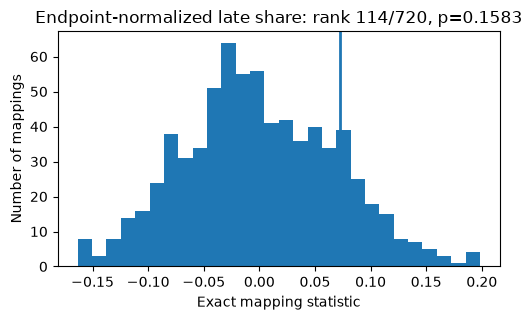

saved: ../figures/sxg24_endpoint_late_share_permutation.png
saved: ../figures/sxg24_endpoint_late_share_permutation.pdf


In [12]:
fig, ax = plt.subplots(figsize=(5.2, 3.3))
ax.hist(primary["null_stats"], bins=28)
ax.axvline(primary["true_stat"], linewidth=2)
ax.set_xlabel("Exact mapping statistic")
ax.set_ylabel("Number of mappings")
ax.set_title(
    f"Endpoint-normalized late share: "
    f"rank {primary['rank']}/720, p={primary['p_exact']:.4f}"
)
fig.tight_layout()

p_png = FIGURES / "sxg24_endpoint_late_share_permutation.png"
p_pdf = FIGURES / "sxg24_endpoint_late_share_permutation.pdf"
fig.savefig(p_png, dpi=200, bbox_inches="tight")
fig.savefig(p_pdf, bbox_inches="tight")
plt.show()

print("saved:", p_png)
print("saved:", p_pdf)


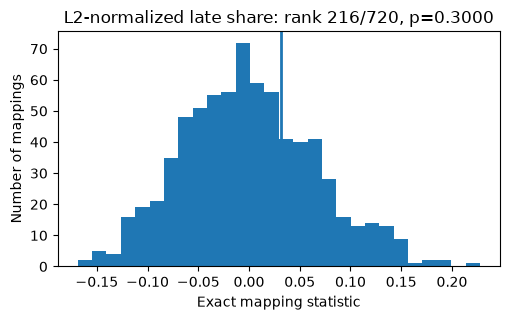

saved: ../figures/sxg24_l2_late_share_permutation.png
saved: ../figures/sxg24_l2_late_share_permutation.pdf


In [13]:
fig, ax = plt.subplots(figsize=(5.2, 3.3))
ax.hist(robust["null_stats"], bins=28)
ax.axvline(robust["true_stat"], linewidth=2)
ax.set_xlabel("Exact mapping statistic")
ax.set_ylabel("Number of mappings")
ax.set_title(
    f"L2-normalized late share: "
    f"rank {robust['rank']}/720, p={robust['p_exact']:.4f}"
)
fig.tight_layout()

p_png = FIGURES / "sxg24_l2_late_share_permutation.png"
p_pdf = FIGURES / "sxg24_l2_late_share_permutation.pdf"
fig.savefig(p_png, dpi=200, bbox_inches="tight")
fig.savefig(p_pdf, bbox_inches="tight")
plt.show()

print("saved:", p_png)
print("saved:", p_pdf)


## 11. Interpretation gate

### If the primary and/or L2 control remains significant

Safe interpretation:

> The same-lineage mapping persists after removing short-context offset and
> overall context-gain amplitude. This argues against a purely affine
> same-family calibration explanation and localizes the affinity partly to the
> relative shape of context response.

Do **not** claim that all calibration, tokenizer, architecture, training-data,
or other lineage-related mechanisms have been eliminated.

### If both normalized controls become null

Safe interpretation:

> The previously observed lineage diagonal is robust after subtracting the
> short-context loss baseline, but it does not survive normalization of total
> context-gain amplitude. The present data therefore cannot separate
> same-lineage dependency response from residual family-specific calibration of
> gain magnitude.

In that case, narrow the paper's lineage claim rather than hiding the null.

### If the two normalizations disagree

Report both. Endpoint normalization is more directly interpretable as a late
fraction; L2 normalization is less sensitive to a small \(U(256)\) denominator.
Use the denominator diagnostics above to decide how much weight to place on the
endpoint-normalized result.
